#### Importing and checking for existance

In [19]:
import inspect
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chisquare, hypergeom
from IPython.display import display
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pandas as pd

#prettyfy
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

#getting csv
csv_path = Path("export.csv")
#if csv isnt there
if not csv_path.exists():
    raise FileNotFoundError("Place export.csv in the notebook folder, or change csv_path.")
raw = pd.read_csv(csv_path)

#### Finds row count, what the values look like, type, and missing values.

In [ ]:
print("Original shape:", raw.shape)
display(raw.head())

print("Columns:", raw.columns.tolist())

print("Types:")
display(raw.dtypes.to_frame("dtype"))

print("Missing values:")
display(raw.isna().sum().to_frame("missing"))

Original shape: (2017, 4)


,Draw Date,Winning Numbers,Multiplier,double_play_winning_numbers
0,10/26/2026,18 26 49 50 54 01,3.0,05 11 14 24 59 08
1,10/24/2026,04 05 15 19 55 19,2.0,03 30 44 50 56 23
2,10/21/2026,01 21 44 50 57 05,2.0,07 23 31 45 59 08
3,10/19/2026,08 31 32 42 48 23,4.0,11 23 24 47 49 11
4,10/17/2026,12 13 24 32 35 11,3.0,13 14 30 52 60 15


Columns: ['Draw Date', 'Winning Numbers', 'Multiplier', 'double_play_winning_numbers']
Types:


,dtype
Draw Date,str
Winning Numbers,str
Multiplier,float64
double_play_winning_numbers,str


Missing values:


,missing
Draw Date,0
Winning Numbers,0
Multiplier,210
double_play_winning_numbers,1954


#### Fixes date formating and filters based on recorded power ball rules (i.e. the range of numbers alowed).

In [21]:
#fixing date
df = raw.copy()
df["Draw Date"] = pd.to_datetime(df["Draw Date"], format="%m/%d/%Y", errors="coerce")
start_date = pd.Timestamp("2015-10-07")
df = df.loc[df["Draw Date"].ge(start_date)].copy()
df = df.sort_values("Draw Date").reset_index(drop=True)

print("Filtered shape:", df.shape)
print("Dates:", df["Draw Date"].min().date(), "to", df["Draw Date"].max().date())
display(df.head())
print("Missing values after filtering:")
display(pd.DataFrame({"count": df.isna().sum(), "percent": (100*df.isna().mean()).round(2)}))

Filtered shape: (1425, 4)
Dates: 2015-10-07 to 2026-10-26


,Draw Date,Winning Numbers,Multiplier,double_play_winning_numbers
0,2015-10-07,18 30 40 48 52 09,3.0,NaN
1,2015-10-10,12 27 29 43 68 01,2.0,NaN
2,2015-10-14,15 20 29 31 40 01,2.0,NaN
3,2015-10-17,48 49 57 62 69 19,3.0,NaN
4,2015-10-21,30 32 42 56 57 11,4.0,NaN


Missing values after filtering:


,count,percent
Draw Date,0,0.00
Winning Numbers,0,0.00
Multiplier,0,0.00
double_play_winning_numbers,1362,95.58


#### Parses each number into its own column for more detailed analysis.

In [23]:
#parsing values
def parse_six(value):
    if pd.isna(value):
        return [np.nan] * 6
    parts = str(value).strip().split()
    if len(parts) != 6:
        return [np.nan] * 6
    try:
        return [int(x) for x in parts]
    except ValueError:
        return [np.nan] * 6

white_cols = [f"White{i}" for i in range(1,6)]
num_cols = white_cols + ["Powerball"]
parsed = pd.DataFrame(df["Winning Numbers"].apply(parse_six).tolist(), columns=num_cols, index=df.index)
df = pd.concat([df, parsed], axis=1)
display(df[["Draw Date"] + num_cols].head())

,Draw Date,White1,White2,White3,White4,White5,Powerball
0,2015-10-07,18,30,40,48,52,9
1,2015-10-10,12,27,29,43,68,1
2,2015-10-14,15,20,29,31,40,1
3,2015-10-17,48,49,57,62,69,19
4,2015-10-21,30,32,42,56,57,11


#### Get rid of any dupes in rows (were none).

In [ ]:
#cleaning dupes
print("Exact duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().copy()
print("Repeated drawing dates:", df["Draw Date"].duplicated().sum())
if df["Draw Date"].duplicated().any():
    display(df.loc[df["Draw Date"].duplicated(keep=False), ["Draw Date", "Winning Numbers"]])

valid = (df[white_cols].notna().all(axis=1)
         & df[white_cols].ge(1).all(axis=1)
         & df[white_cols].le(69).all(axis=1)
         & df["Powerball"].between(1,26)
         & df[white_cols].nunique(axis=1).eq(5))
print("Invalid main drawings:", (~valid).sum())

if (~valid).any():
    display(df.loc[~valid, ["Draw Date", "Winning Numbers"]])
clean = df.loc[valid].copy()

for col in num_cols:
    clean[col] = clean[col].astype(int)
clean["Multiplier"] = pd.to_numeric(clean["Multiplier"], errors="coerce")

print("Cleaned main-draw rows:", len(clean))

Exact duplicate rows: 0
Repeated drawing dates: 0
Invalid main drawings: 0
Cleaned main-draw rows: 1425


#### Gives clean overview fo the different columns, to get odd count and even count for future finding of distribution.

In [ ]:
#cleaning data
clean["Year"] = clean["Draw Date"].dt.year
clean["Month"] = clean["Draw Date"].dt.month
clean["Weekday"] = clean["Draw Date"].dt.day_name()
clean["White_Sum"] = clean[white_cols].sum(axis=1)
clean["Odd_Count"] = clean[white_cols].mod(2).sum(axis=1).astype(int)
clean["Even_Count"] = 5 - clean["Odd_Count"]
clean["Low_Count"] = clean[white_cols].le(34).sum(axis=1)
clean["High_Count"] = 5 - clean["Low_Count"]

print("Numeric summary:")
display(clean[["White_Sum", "Odd_Count", "Low_Count", "Multiplier"]].describe().T)
print("Weekday category counts:")
display(clean["Weekday"].value_counts())
print("Odd-count category counts:")
display(clean["Odd_Count"].value_counts().sort_index())

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
White_Sum,1425.0,176.666667,43.016138,52.0,149.0,177.0,206.0,299.0
Odd_Count,1425.0,2.547368,1.100004,0.0,2.0,3.0,3.0,5.0
Low_Count,1425.0,2.444912,1.080316,0.0,2.0,2.0,3.0,5.0
Multiplier,1425.0,2.682807,1.173989,2.0,2.0,2.0,3.0,10.0


Weekday category counts:


Weekday
Wednesday    577
Saturday     577
Monday       271
Name: count, dtype: int64

Odd-count category counts:


Odd_Count
0     37
1    208
2    443
3    453
4    243
5     41
Name: count, dtype: int64

#### Encodes categorical variables.

In [27]:
#encoding
encoded = pd.get_dummies(clean[["Weekday"]], dtype=int)
print("Encoded feature columns:", encoded.columns.tolist())
display(encoded.head())

Encoded feature columns: ['Weekday_Monday', 'Weekday_Saturday', 'Weekday_Wednesday']


,Weekday_Monday,Weekday_Saturday,Weekday_Wednesday
0,0,0,1
1,0,1,0
2,0,0,1
3,0,1,0
4,0,0,1


#### Gives general plots of parsed powerball collumns.

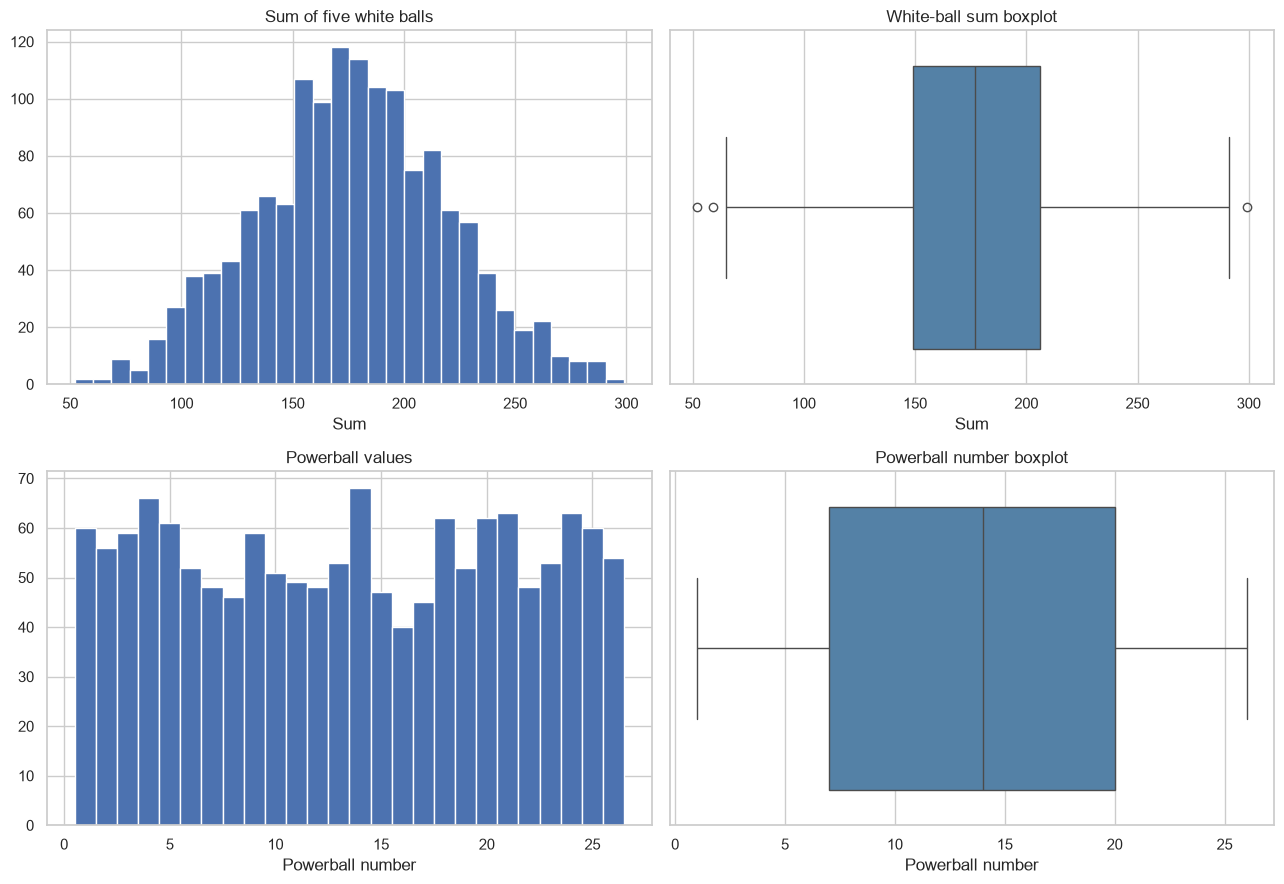

In [ ]:
#plotting
fig, axes = plt.subplots(2,2,figsize=(13,9))

axes[0,0].hist(clean["White_Sum"], bins=30)
axes[0,0].set(title="Sum of five white balls", xlabel="Sum")
sns.boxplot(x=clean["White_Sum"], ax=axes[0,1], color="steelblue")

axes[0,1].set(title="White-ball sum boxplot", xlabel="Sum")
axes[1,0].hist(clean["Powerball"], bins=np.arange(0.5,27.5,1))
axes[1,0].set(title="Powerball values", xlabel="Powerball number")
sns.boxplot(x=clean["Powerball"], ax=axes[1,1], color="steelblue")

axes[1,1].set(title="Powerball number boxplot", xlabel="Powerball number")
plt.tight_layout(); plt.show()

#### Finds frequencies in the balls.

Ten most frequent white balls:


,Count
21,128
61,126
64,125
28,121
32,120
23,119
36,118
27,118
33,118
63,117


Ten least frequent white balls:


,Count
13,78
26,84
46,84
34,85
49,85
25,91
41,92
22,92
51,92
35,93


Five most frequent Powerballs:


,Count
Powerball,
14,68
4,66
21,63
24,63
18,62


Five least frequent Powerballs:


,Count
Powerball,
16,40
17,45
8,46
15,47
12,48


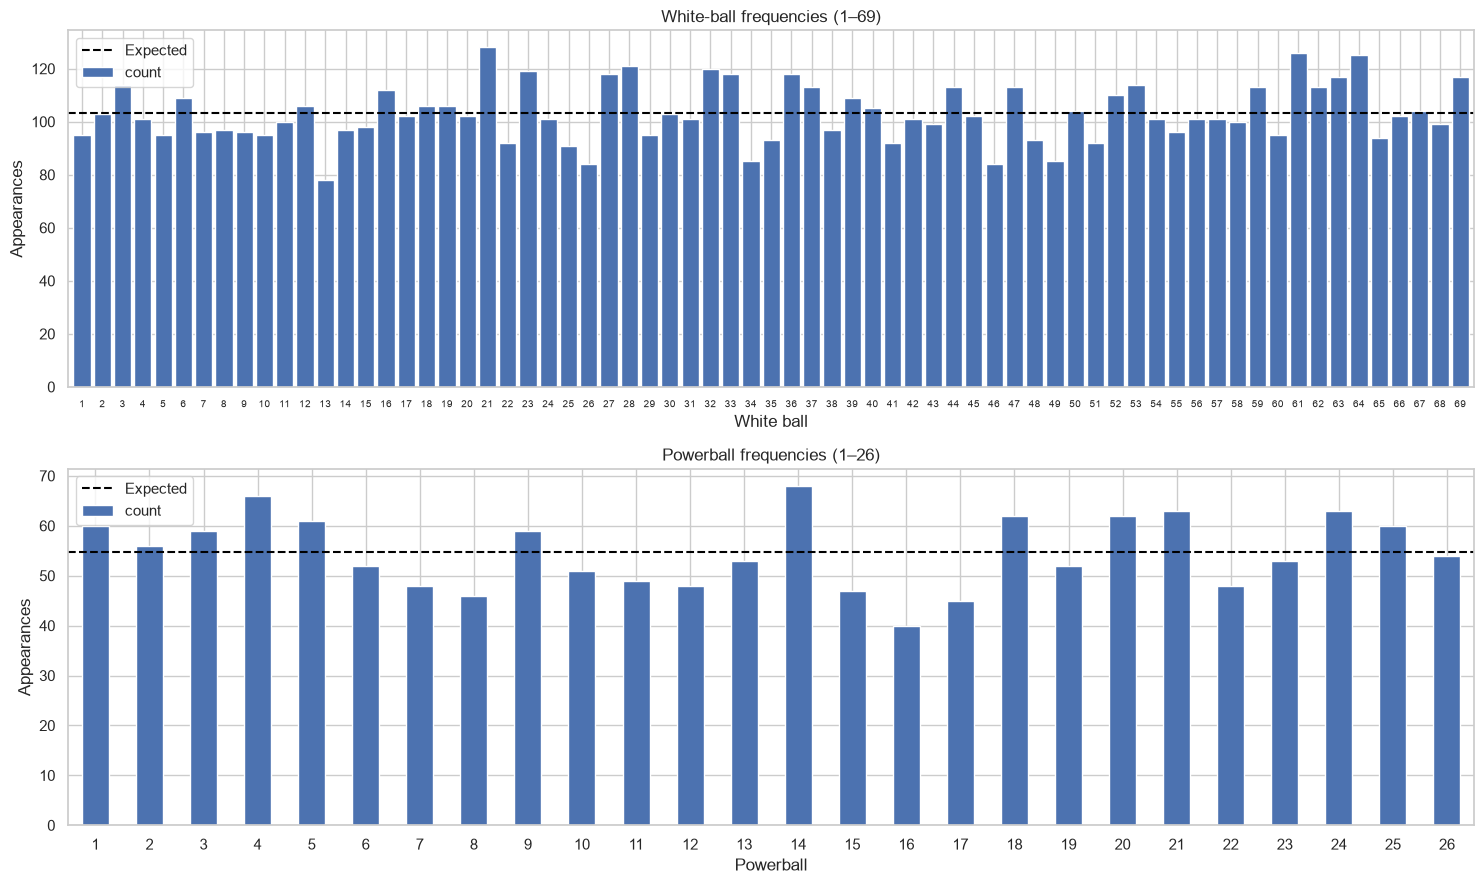

In [ ]:
#finding trends
white_values = clean[white_cols].to_numpy().ravel()
white_freq = pd.Series(white_values).value_counts().reindex(range(1,70), fill_value=0).sort_index()
pb_freq = clean["Powerball"].value_counts().reindex(range(1,27), fill_value=0).sort_index()

print("Ten most frequent white balls:")
display(white_freq.sort_values(ascending=False).head(10).to_frame("Count"))

print("Ten least frequent white balls:")
display(white_freq.sort_values().head(10).to_frame("Count"))

print("Five most frequent Powerballs:")
display(pb_freq.sort_values(ascending=False).head(5).to_frame("Count"))

print("Five least frequent Powerballs:")
display(pb_freq.sort_values().head(5).to_frame("Count"))

fig, axes = plt.subplots(2,1,figsize=(15,9))
white_freq.plot.bar(ax=axes[0], width=.85)

axes[0].axhline(len(clean)*5/69, linestyle="--", color="black", label="Expected")
axes[0].set(title="White-ball frequencies (1–69)", xlabel="White ball", ylabel="Appearances")
axes[0].legend(); axes[0].tick_params(axis="x", labelsize=7, rotation=0)
pb_freq.plot.bar(ax=axes[1])

axes[1].axhline(len(clean)/26, linestyle="--", color="black", label="Expected")
axes[1].set(title="Powerball frequencies (1–26)", xlabel="Powerball", ylabel="Appearances")
axes[1].legend(); axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

#### Gets the chi-squared from actual frequency to the obseved frequency to check null hypothesis.

In [31]:
#chi-square test
N = len(clean)
white_expected = np.repeat(5*N/69, 69)
pb_expected = np.repeat(N/26, 26)
white_stat, white_p_naive = chisquare(white_freq.values, f_exp=white_expected)
pb_stat, pb_p = chisquare(pb_freq.values, f_exp=pb_expected)

print(f"Draws: {N:,}")
print(f"White balls: chi-square={white_stat:.3f}, df=68, conventional p={white_p_naive:.5f}")
print(f"Powerballs:  chi-square={pb_stat:.3f}, df=25, p={pb_p:.5f}")
print("Powerball decision:", "Reject H0" if pb_p < .05 else "Fail to reject H0")

Draws: 1,425
White balls: chi-square=77.583, df=68, conventional p=0.19973
Powerballs:  chi-square=24.267, df=25, p=0.50397
Powerball decision: Fail to reject H0


#### Simulates random balls against expected random balls.

Simulation-based white-ball p-value: 0.11196
White-ball decision: Fail to reject H0


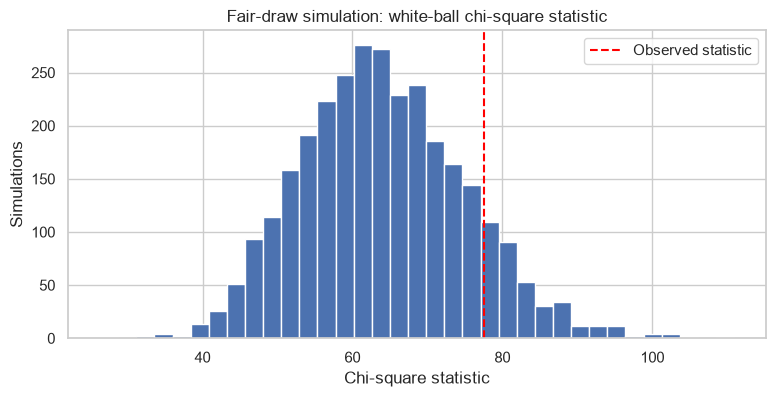

In [32]:
rng = np.random.default_rng(2026)
SIMS = 3000
sim_stats = np.empty(SIMS)
expected = 5*N/69

# Vectorized simulation in batches to avoid storing every simulation at once.
for i in range(SIMS):
    # Randomly select 5 distinct balls for each of N simulated drawings.
    picks = np.argpartition(rng.random((N,69)), kth=4, axis=1)[:,:5]
    counts = np.bincount(picks.ravel(), minlength=69)
    sim_stats[i] = np.sum((counts-expected)**2/expected)
white_p_sim = (1 + (sim_stats >= white_stat).sum()) / (SIMS + 1)
print(f"Simulation-based white-ball p-value: {white_p_sim:.5f}")
print("White-ball decision:", "Reject H0" if white_p_sim < .05 else "Fail to reject H0")
plt.figure(figsize=(9,4))
plt.hist(sim_stats, bins=35)
plt.axvline(white_stat, color="red", linestyle="--", label="Observed statistic")
plt.title("Fair-draw simulation: white-ball chi-square statistic")
plt.xlabel("Chi-square statistic"); plt.ylabel("Simulations"); plt.legend(); plt.show()

#### Checks if p-value is sufficient for the balls.

In [ ]:
#summary
results = pd.DataFrame([
    {"Test":"White balls (simulation-based)", "Statistic":white_stat, "p_value":white_p_sim,
     "Decision":"Reject H0" if white_p_sim < .05 else "Fail to reject H0"},
    {"Test":"Powerball (chi-square)", "Statistic":pb_stat, "p_value":pb_p,
     "Decision":"Reject H0" if pb_p < .05 else "Fail to reject H0"}
])
display(results)
for row in results.itertuples():
    print(f"{row.Test}: {row.Decision} (p={row.p_value:.4f}).")

,Test,Statistic,p_value,Decision
0,White balls (simulation-based),77.583158,0.111963,Fail to reject H0
1,Powerball (chi-square),24.267368,0.503971,Fail to reject H0


White balls (simulation-based): Fail to reject H0 (p=0.1120).
Powerball (chi-square): Fail to reject H0 (p=0.5040).


#### Shows the pattern with high value and low value balls.

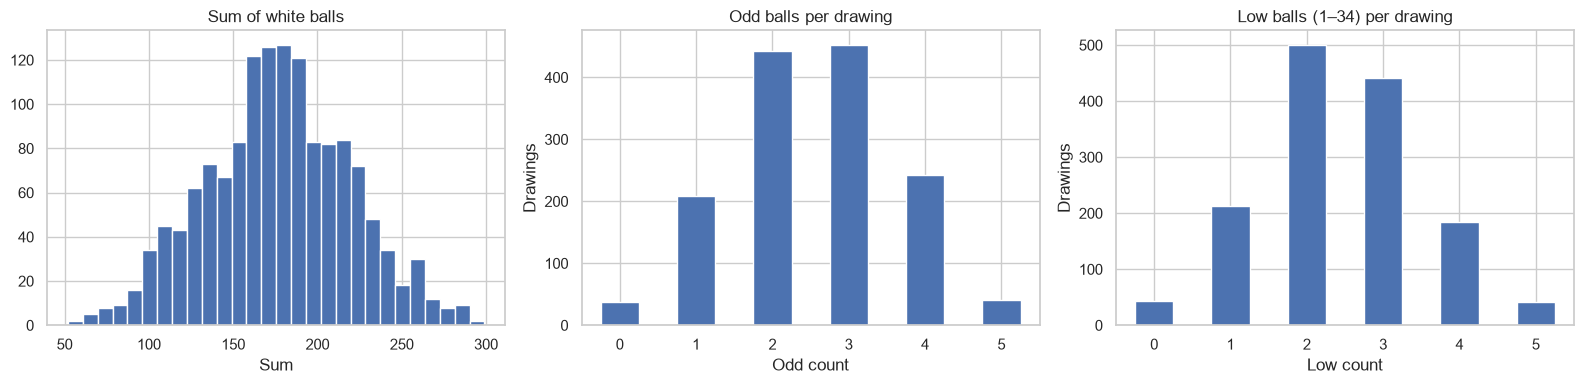

,Observed,Expected under fair draw
Odd_Count,,
0,37,35.28
1,208,205.81
2,443,451.46
3,453,465.56
4,243,225.73
5,41,41.16


Mean sum: 176.67
Median sum: 177.0


In [35]:
#um/low-high patterns

fig, axes = plt.subplots(1,3,figsize=(16,4))
axes[0].hist(clean["White_Sum"], bins=28)
axes[0].set(title="Sum of white balls", xlabel="Sum")
odd_counts = clean["Odd_Count"].value_counts().reindex(range(6), fill_value=0).sort_index()
low_counts = clean["Low_Count"].value_counts().reindex(range(6), fill_value=0).sort_index()
odd_counts.plot.bar(ax=axes[1])
axes[1].set(title="Odd balls per drawing", xlabel="Odd count", ylabel="Drawings")
low_counts.plot.bar(ax=axes[2])
axes[2].set(title="Low balls (1–34) per drawing", xlabel="Low count", ylabel="Drawings")
for ax in axes[1:]: ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

odd_expected = hypergeom.pmf(np.arange(6), M=69, n=35, N=5)*N
odd_compare = pd.DataFrame({"Observed":odd_counts, "Expected under fair draw":odd_expected})
display(odd_compare.round(2))
print("Mean sum:", round(clean["White_Sum"].mean(),2))
print("Median sum:", round(clean["White_Sum"].median(),2))

#### Gives overview of categorical data not referenced yet for the balls.

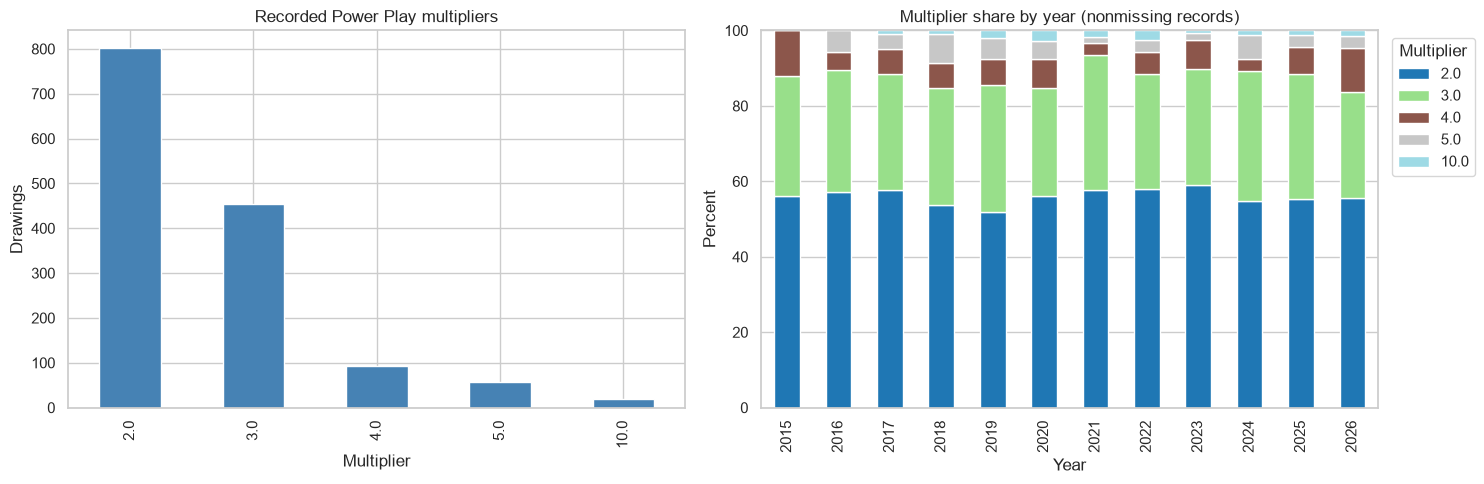

Multiplier,2.0,3.0,4.0,5.0,10.0
Year,,,,,
2015,56.0,32.0,12.0,0.0,0.0
2016,57.1,32.4,4.8,5.7,0.0
2017,57.7,30.8,6.7,3.8,1.0
2018,53.8,30.8,6.7,7.7,1.0
2019,51.9,33.7,6.7,5.8,1.9
2020,56.2,28.6,7.6,4.8,2.9
2021,57.7,35.8,3.3,1.6,1.6
2022,58.0,30.6,5.7,3.2,2.5
2023,59.0,30.8,7.7,1.9,0.6


In [42]:
#mults/power play

multiplier_counts = clean["Multiplier"].value_counts().sort_index()
yearly_mult = pd.crosstab(clean["Year"], clean["Multiplier"], normalize="index")*100
fig, ax = plt.subplots(1,2,figsize=(15,5))

multiplier_counts.plot.bar(ax=ax[0], color="steelblue")
ax[0].set(title="Recorded Power Play multipliers", xlabel="Multiplier", ylabel="Drawings")

yearly_mult.plot.bar(stacked=True, ax=ax[1], colormap="tab20")
ax[1].set(title="Multiplier share by year (nonmissing records)", xlabel="Year", ylabel="Percent")
ax[1].legend(title="Multiplier", bbox_to_anchor=(1.01,1), loc="upper left")

plt.tight_layout(); plt.show()
display(yearly_mult.round(1))

#### Compares power play entries vs. original entries on the same date.

Available Double Play strings: 63
Valid Double Play records: 63
Mean main-draw sum on paired dates: 172.03
Mean Double Play sum: 166.68


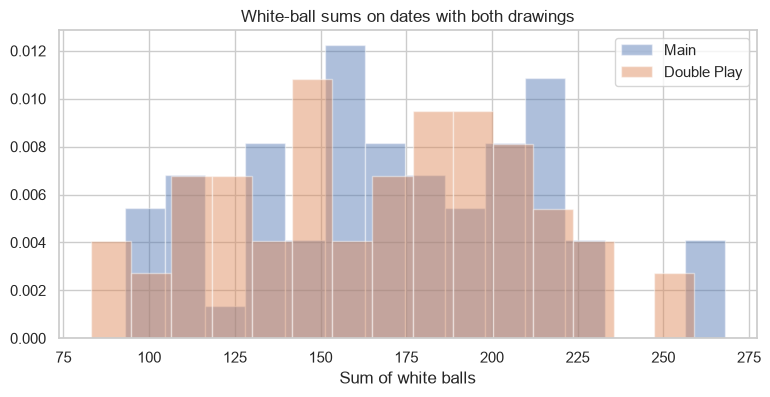

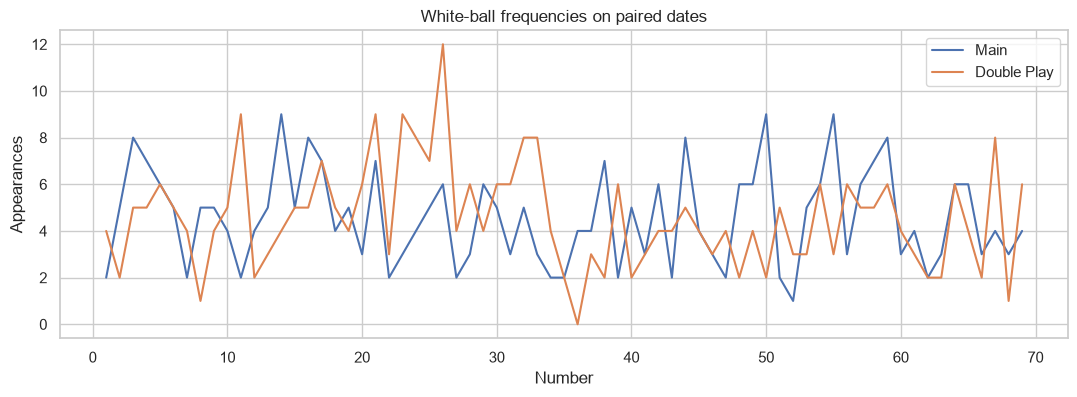

In [43]:
#power play comparison

dp_cols = [f"DPWhite{i}" for i in range(1,6)] + ["DP_Powerball"]
dp_parsed = pd.DataFrame(clean["double_play_winning_numbers"].apply(parse_six).tolist(), columns=dp_cols, index=clean.index)
with_dp = pd.concat([clean, dp_parsed], axis=1)
valid_dp = (with_dp[dp_cols].notna().all(axis=1)
    & with_dp[dp_cols[:5]].ge(1).all(axis=1)
    & with_dp[dp_cols[:5]].le(69).all(axis=1)
    & with_dp["DP_Powerball"].between(1,26)
    & with_dp[dp_cols[:5]].nunique(axis=1).eq(5))

print("Available Double Play strings:", clean["double_play_winning_numbers"].notna().sum())
print("Valid Double Play records:", valid_dp.sum())

paired = with_dp.loc[valid_dp].copy()
for col in dp_cols: paired[col] = paired[col].astype(int)

if not paired.empty:
    paired["DP_Sum"] = paired[dp_cols[:5]].sum(axis=1)
    paired["Main_Sum"] = paired[white_cols].sum(axis=1)
    print("Mean main-draw sum on paired dates:", round(paired["Main_Sum"].mean(),2))
    print("Mean Double Play sum:", round(paired["DP_Sum"].mean(),2))
    plt.figure(figsize=(9,4))
    plt.hist(paired["Main_Sum"], bins=15, density=True, alpha=.45, label="Main")
    plt.hist(paired["DP_Sum"], bins=15, density=True, alpha=.45, label="Double Play")
    plt.title("White-ball sums on dates with both drawings")
    plt.xlabel("Sum of white balls"); plt.legend(); plt.show()
    main_paired_freq = pd.Series(paired[white_cols].to_numpy().ravel()).value_counts().reindex(range(1,70),fill_value=0)
    dp_freq = pd.Series(paired[dp_cols[:5]].to_numpy().ravel()).value_counts().reindex(range(1,70),fill_value=0)
    pd.DataFrame({"Main":main_paired_freq,"Double Play":dp_freq}).plot(figsize=(13,4))
    plt.title("White-ball frequencies on paired dates")
    plt.xlabel("Number"); plt.ylabel("Appearances"); plt.show()

#### Gives a conclusion that updates with data changed in the previous code. <br>
### Limitations: <br>
* doesnt include payouts, jackpots, ticket purchases, or winner counts <br>
* only a cubset has double play resultts (not in general analysis) <br>
* a non significant test doesn't prove fairness <br>
* a statistical significance alone doesn't establish prediction strat <br>
* observed number frequencies can and will change naturally

In [ ]:
#updateable conclusion

white_verdict = ("shows evidence of nonuniform frequencies" if white_p_sim < .05
                 else "does not show statistically significant evidence of nonuniform frequencies")
pb_verdict = ("shows evidence of nonuniform frequencies" if pb_p < .05
              else "does not show statistically significant evidence of nonuniform frequencies")
print(f"From {len(clean):,} valid drawings beginning October 7, 2015, the white-ball analysis {white_verdict} "
      f"(simulation p={white_p_sim:.4f}). The Powerball analysis {pb_verdict} (p={pb_p:.4f}).")
print("These results describe historical observations, not a method for predicting independent future draws.")
print("The dataset cannot answer whether purchasing tickets or multipliers is profitable.")
print("Valid Double Play records:", len(paired))

From 1,425 valid drawings beginning October 7, 2015, the white-ball analysis does not show statistically significant evidence of nonuniform frequencies (simulation p=0.1120). The Powerball analysis does not show statistically significant evidence of nonuniform frequencies (p=0.5040).
These results describe historical observations, not a method for predicting independent future draws.
The dataset cannot answer whether purchasing tickets or multipliers is profitable.
Valid Double Play records: 63


### References <br>
* Data.gov: Lottery Powerball Winning Numbers: Beginning 2010 https://catalog.data.gov/dataset/lottery-powerball-winning-numbers-beginning-2010
* Powerball official site — rules and game information https://www.powerball.com/